In [1]:
import joblib
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from xgboost import plot_importance
from sklearn.metrics import classification_report, f1_score, auc, roc_curve
import shap
shap.initjs()
import utils

from sklearn.datasets import load_wine
from sklearn.inspection import partial_dependence, PartialDependenceDisplay
from pycebox.ice import ice, ice_plot
from lime import lime_tabular

def predict_proba_with_names(x):
    x_df = pd.DataFrame(x, columns=X_test.columns.tolist())
    return pipeline_rf.predict_proba(x_df)

/Users/epiphaneegah/Documents/fraud-detection-gcp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = "gs://data-epip/test/paysim.parquet"
train_pdf = pd.read_parquet(path, engine='pyarrow').sample(10000)


X_test, y_test = train_pdf.drop("isFraud", axis=1), train_pdf["isFraud"]
X_test.drop(["nameOrig", "nameDest", "step", "isFlaggedFraud"], axis=1, inplace=True)

In [3]:
pipeline_xgb = joblib.load("../output/xgboost-new-v2.pkl")

### Interprétation globale du modèle

#### Permutation importance et importance 

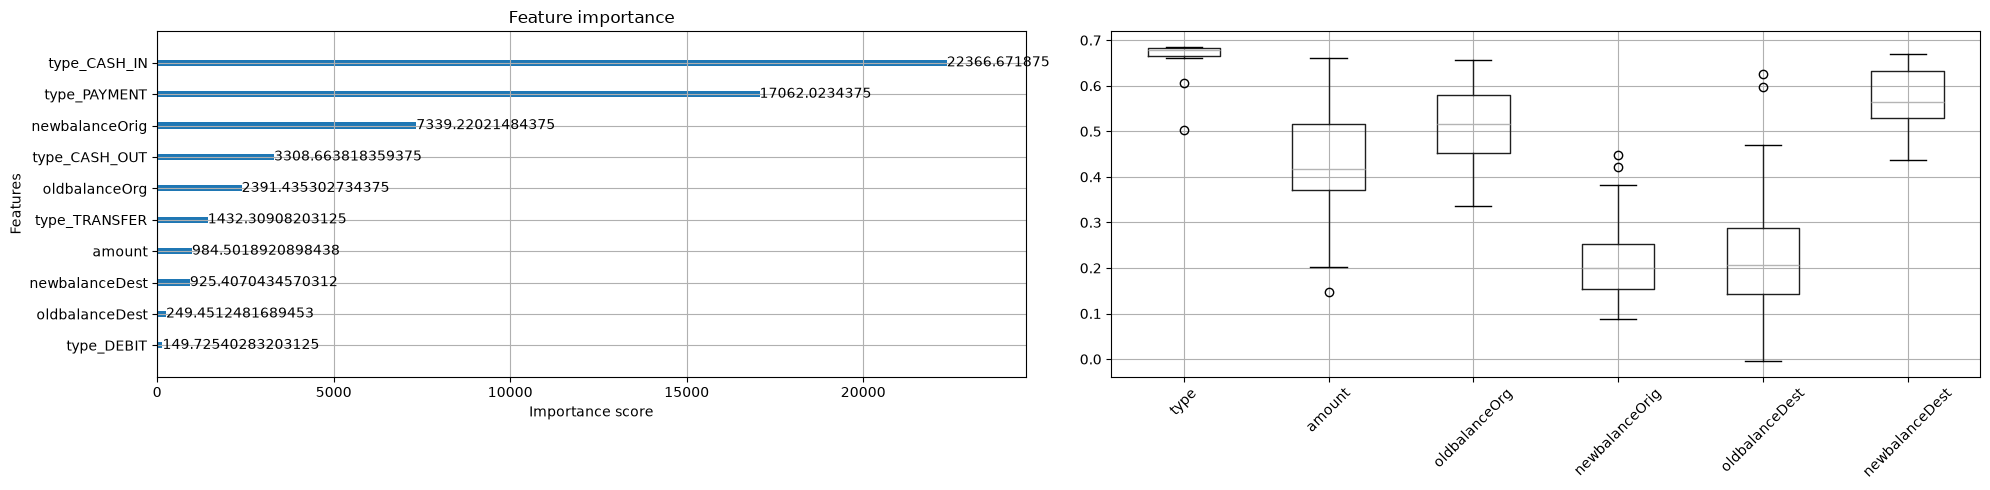

In [4]:
plt.rcParams["figure.figsize"] = (20, 5)
ax = plt.subplot(121)
plot_importance(pipeline_xgb.named_steps['classifier'], max_num_features=10, importance_type='gain', ax=ax)

ax = plt.subplot(122)
r = permutation_importance(
    pipeline_xgb,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=30,
    random_state=42,
)

pd.DataFrame(
    r.importances.T,
    columns=X_test.columns
).boxplot(rot=45, ax=ax)

plt.tick_params(axis='both', labelsize=10)
plt.tight_layout()
plt.show()

#### Shap explainer

In [5]:
# 2. Appliquer preprocess_tr
X_test_tr = pipeline_xgb.named_steps["clean_data"].transform(X_test)

# 3. Appliquer le ColumnTransformer
X_test_processed = pipeline_xgb.named_steps["preprocess"].transform(X_test_tr)

# 4. Récupérer le XGBoost entraîné
model_xgb = pipeline_xgb.named_steps["classifier"]  # à adapter au nom exact de ton step

# 5. SHAP
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer(X_test_processed)

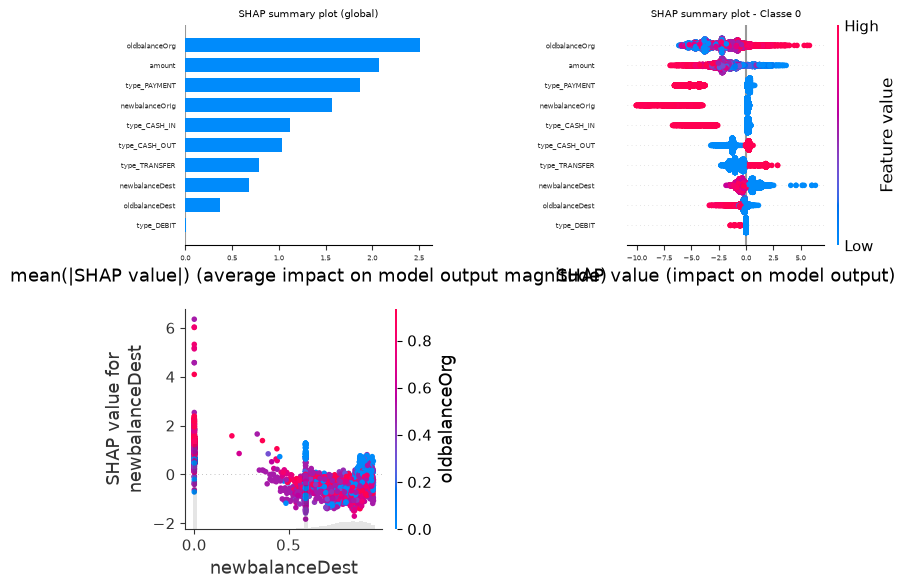

<Figure size 700x3000 with 0 Axes>

In [6]:
plt.rcParams["figure.figsize"] = (7, 30)

class_name = 0

ax = plt.subplot(221)
shap.summary_plot(shap_values, X_test_processed, plot_type="bar", show=False)

ax = plt.gca()
ax.set_title("SHAP summary plot (global)", fontsize=7)
ax.tick_params(axis='y', labelsize=5)  # noms des features
ax.tick_params(axis='x', labelsize=5)

ax = plt.subplot(222)
shap.summary_plot(shap_values, X_test_processed, show=False)
ax = plt.gca()
ax.set_title(f"SHAP summary plot - Classe {class_name}", fontsize=7)
ax.tick_params(axis='y', labelsize=5)  # noms des features
ax.tick_params(axis='x', labelsize=5)

# Dépendance plot
ax = plt.subplot(223)
shap.plots.scatter(shap_values[:, "newbalanceDest"], color=shap_values[:, :], ax=ax)

plt.tight_layout()
plt.show()

### Interprétation local

In [7]:
i = 0          # index de l'observation à expliquer
class_idx = 1  # classe à expliquer (0, 1 ou 2)

shap.plots.force(shap_values[i])

In [8]:
# class_idx = 1  # la classe à visualiser
# shap.plots.force(
#     explainer.expected_value,
#     shap_values.values,
#     X_test_processed
# )

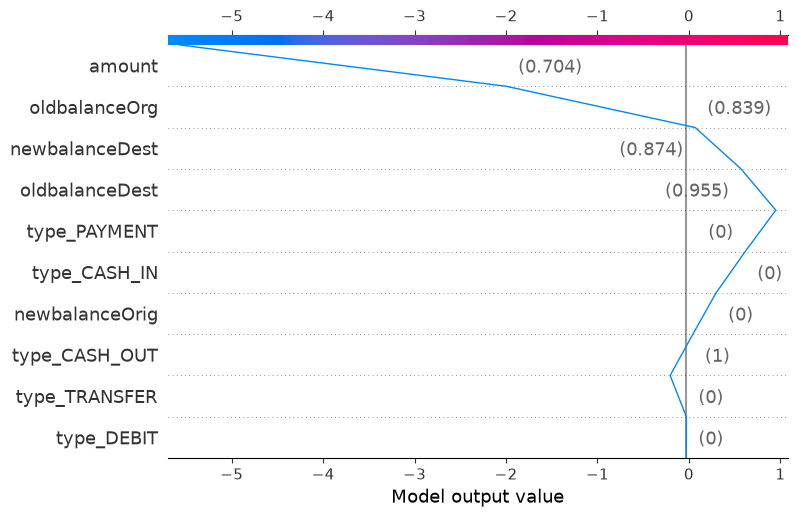

In [9]:
shap.decision_plot(
    explainer.expected_value,   # base value pour cette classe
    shap_values.values[i, :],   # SHAP values pour cette observation
    X_test_processed.iloc[i, :],                          # valeurs réelles des variables
    feature_names=X_test_processed.columns.tolist()
)